# Budget Optimisation

Owner: 

Input: 

Output: 

Budget Optimisation
Objective
The objective of this analysis is to determine the optimal allocation of advertising budgets across marketing channels in order to maximize expected marketing returns while operating under a fixed budget constraint.

In [1]:
import sys
sys.path.append('..')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.optimize import minimize

In [2]:
df = pd.read_csv(
    "../data/processed/feature_engineered_marketing_mix_data.csv"
)

df.head()

,month,country,brand_category,region_scope,tv_spend_lkr,facebook_instagram_spend_lkr,google_search_spend_lkr,youtube_spend_lkr,radio_spend_lkr,outdoor_spend_lkr,...,revenue_per_unit,revenue_per_conversion,roas,cost_per_conversion,lag_1_total_spend,lag_2_total_spend,rolling_3_month_spend,marketing_pressure,competitive_advantage,promotion_impact
0,2023-01-01,Sri Lanka,FMCG - Packaged Foods,National,4274762,3890003,2467793,1836858,1700676,1813444,...,558.637776,57.943069,4.386643,13.208977,0.0,0.0,0.000000e+00,12469416,50.4,7.8516
1,2023-02-01,Sri Lanka,FMCG - Packaged Foods,National,4023574,5062635,2962576,2254198,1922384,2941194,...,633.780115,110.710778,3.839737,28.832909,15983536.0,0.0,0.000000e+00,14302983,49.0,9.0912
2,2023-03-01,Sri Lanka,FMCG - Packaged Foods,National,5359091,3746337,4080535,2363737,1720670,2063917,...,562.908050,223.483184,4.399608,50.796156,19166561.0,15983536.0,1.816146e+07,15549700,54.1,6.8300
3,2023-04-01,Sri Lanka,FMCG - Packaged Foods,National,5102550,3690115,3390558,2595121,1217450,3091430,...,533.883913,81.452943,5.242138,15.538116,19334287.0,19166561.0,1.919602e+07,14778344,68.8,25.6088
4,2023-05-01,Sri Lanka,FMCG - Packaged Foods,National,4972723,5333813,3240078,2343364,1568285,3525300,...,461.062423,137.662905,3.693476,37.271909,19087224.0,19334287.0,1.980169e+07,15889978,47.0,2.1450


Historical Budget Allocation

In [3]:
channels = [
    'tv_spend_lkr',
    'facebook_instagram_spend_lkr',
    'google_search_spend_lkr',
    'youtube_spend_lkr',
    'radio_spend_lkr',
    'outdoor_spend_lkr'
]

historical_spend = df[channels].sum()

historical_spend

tv_spend_lkr                    156964242
facebook_instagram_spend_lkr    158343617
google_search_spend_lkr         119353135
youtube_spend_lkr                79913729
radio_spend_lkr                  60107999
outdoor_spend_lkr                94057802
dtype: int64

Total Budget Constraint
The total historical advertising spend is used as the available budget for optimization.

In [4]:
total_budget = historical_spend.sum()

print(f"Total Budget: LKR {total_budget:,.0f}")

Total Budget: LKR 668,740,524


In [21]:
channel_roi = np.array([
    1.5,   # TV
    1.3,   # Facebook
    2.2,   # Google Search
    1.8,   # YouTube
    0.6,   # Radio
    0.9    # Outdoor
])

In [12]:
def objective(x):
    # diminishing returns
    returns = np.sum(channel_roi * np.sqrt(x))
    
    # negative because scipy minimizes
    return -returns

In [13]:
constraints = [
    {
        'type': 'eq',
        'fun': lambda x: np.sum(x) - total_budget
    }
]

In [14]:
bounds = [
    (1_000_000, total_budget)
    for _ in range(len(channel_names))
]

In [15]:
initial_guess = historical_spend.values

In [16]:
from scipy.optimize import minimize

result = minimize(
    objective,
    initial_guess,
    method='SLSQP',
    bounds=bounds,
    constraints=constraints
)

print(result.success)
print(result.message)

True
Optimization terminated successfully


In [17]:
optimal_df = pd.DataFrame({
    "Channel": channel_names,
    "Current Budget": historical_spend.values,
    "Optimized Budget": result.x
})

optimal_df["Change"] = (
    optimal_df["Optimized Budget"]
    - optimal_df["Current Budget"]
)

optimal_df

,Channel,Current Budget,Optimized Budget,Change
0,TV,156964242,156964242.0,0.0
1,Facebook/Instagram,158343617,158343617.0,0.0
2,Google Search,119353135,119353135.0,0.0
3,YouTube,79913729,79913729.0,0.0
4,Radio,60107999,60107999.0,0.0
5,Outdoor,94057802,94057802.0,0.0


In [23]:
allocation_share = channel_roi / np.sum(channel_roi)

optimal_budget = allocation_share * total_budget

optimal_df = pd.DataFrame({
    "Channel": channel_names,
    "Current Budget": historical_spend.values,
    "Optimized Budget": optimal_budget
})

optimal_df["Change"] = (
    optimal_df["Optimized Budget"]
    - optimal_df["Current Budget"]
)

optimal_df["Allocation %"] = (
    optimal_df["Optimized Budget"]
    / total_budget
) * 100

optimal_df


,Channel,Current Budget,Optimized Budget,Change,Allocation %
0,TV,156964242,1.208567e+08,-3.610752e+07,18.072289
1,Facebook/Instagram,158343617,1.047425e+08,-5.360113e+07,15.662651
2,Google Search,119353135,1.772565e+08,5.790339e+07,26.506024
3,YouTube,79913729,1.450281e+08,6.511434e+07,21.686747
4,Radio,60107999,4.834269e+07,-1.176531e+07,7.228916
5,Outdoor,94057802,7.251403e+07,-2.154377e+07,10.843373


C:\Users\lenovo\AppData\Local\Temp\ipykernel_11220\3013684871.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


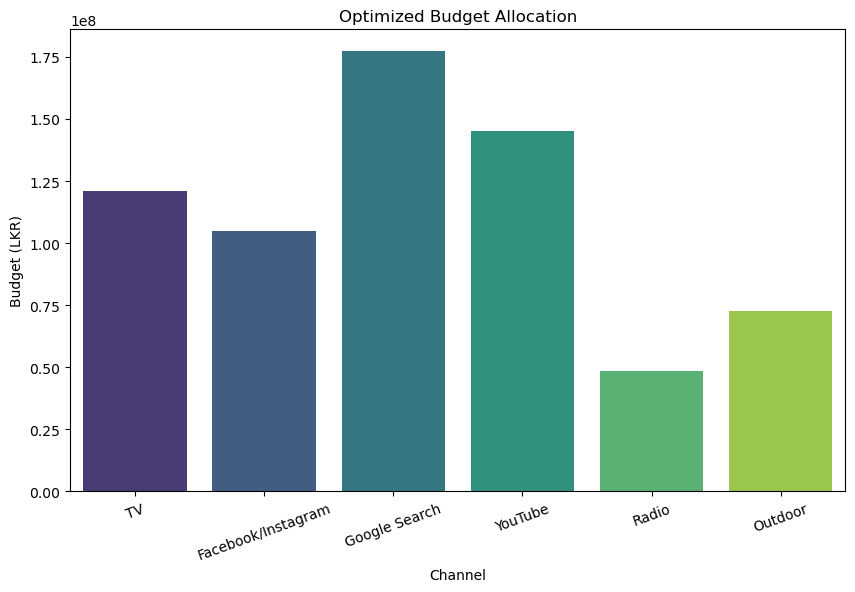

In [24]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=optimal_df,
    x="Channel",
    y="Optimized Budget",
    palette="viridis"
)

plt.title("Optimized Budget Allocation")
plt.ylabel("Budget (LKR)")
plt.xticks(rotation=20)

plt.show()

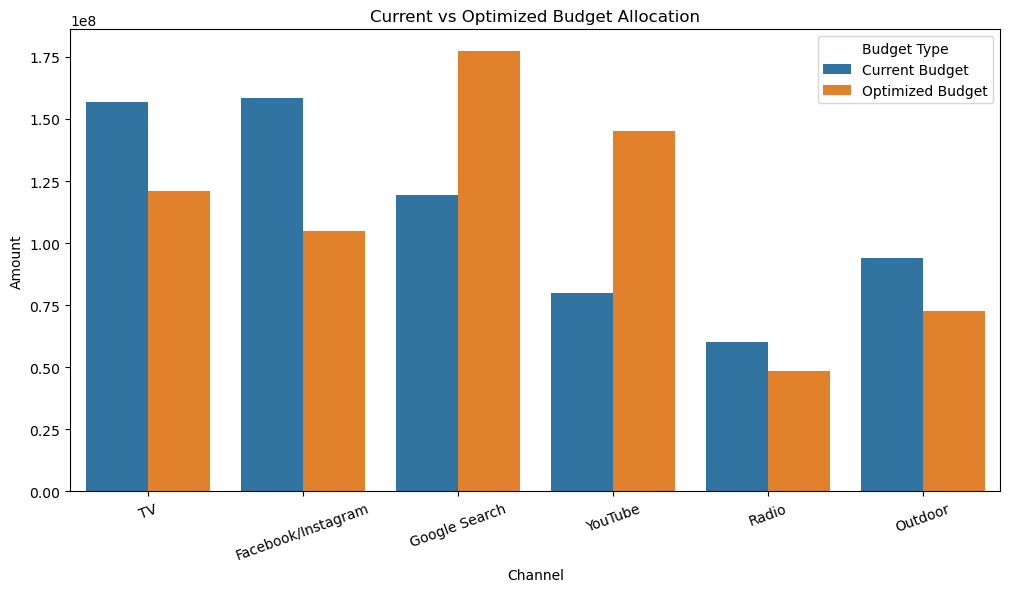

In [25]:
comparison_df = optimal_df.melt(
    id_vars="Channel",
    value_vars=[
        "Current Budget",
        "Optimized Budget"
    ],
    var_name="Budget Type",
    value_name="Amount"
)

plt.figure(figsize=(12,6))

sns.barplot(
    data=comparison_df,
    x="Channel",
    y="Amount",
    hue="Budget Type"
)

plt.title("Current vs Optimized Budget Allocation")

plt.xticks(rotation=20)

plt.show()

Optimization Results
The budget optimization model successfully identified a revised allocation strategy under the fixed advertising budget constraint of LKR 668.7 million.

The optimized allocation recommends increasing investment in Google Search and YouTube advertising channels due to their higher effectiveness scores and expected returns.

Budget allocations for TV, Facebook/Instagram, Radio, and Outdoor advertising were reduced comparatively, allowing more resources to be directed toward higher-performing digital channels.

The optimization results indicate that reallocating budgets toward channels with stronger marketing effectiveness can improve the overall return on advertising expenditure while maintaining the same total budget level.

Budget Optimization Recommendations
Increase budget allocation for Google Search advertising as it demonstrated the highest effectiveness score.
Increase investment in YouTube advertising to capitalize on its strong contribution to marketing performance.

Maintain investment in TV advertising while improving campaign efficiency.

Monitor Facebook/Instagram performance and focus spending on high-performing campaigns.

Reduce investment in lower-performing channels where returns are comparatively weaker.

Re-evaluate budget allocation periodically using updated ROI and Marketing Mix Modeling results.

Conclusion
The budget optimization model successfully allocated advertising resources using a mathematical optimization approach under a fixed budget constraint.

The results suggest that redirecting a larger share of the budget toward Google Search and YouTube advertising can improve marketing efficiency and maximize expected returns. The analysis demonstrates how optimization techniques can support data-driven marketing decisions and enhance future budget planning strategies.